# Automated Malaria Parasite Detection in Thin Blood Smears Using a CNN
## Submission 1 — Dataset, Exploratory Data Analysis and Related Work

**Course:** CSE366 Artificial Intelligence  **Group:** 6

| Name | Student ID |
|---|---|
| Tahmid Aqib | 2024-1-60-225 |
| Rejoanur Rahman | 2024-1-60-245 |
| Mahmudur Rahaman Pial | 2024-1-60-177 |
| Sayem Siddiq | 2024-1-60-298 |

**Contents:** A. Dataset information · B. Exploratory data analysis · C. Related work summary

## A. Dataset information

| Item | Details |
|---|---|
| **Name** | Malaria Cell Images Dataset ("Cell Images for Detecting Malaria") |
| **Original source** | U.S. National Library of Medicine (NLM), Lister Hill National Center for Biomedical Communications, NIH — released with Rajaraman et al. (2018) |
| **Source link (used here)** | https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria |
| **Licence** | NIH/NLM public research release; the companion papers are CC0 (public domain). *Kaggle mirror licence: see the "License" field on the Kaggle page.* |
| **Year** | 2018 (NIH release and Kaggle upload, December 2018) |
| **Task type** | Binary classification |
| **Classes (2)** | `Parasitized` (red blood cell contains *Plasmodium*), `Uninfected` |
| **Total images** | 27,558 single-cell images |
| **Per-class counts** | Parasitized: 13,779 · Uninfected: 13,779 (verified in Section B) |
| **Image size** | Variable — each image is one segmented red blood cell cropped to its bounding box (measured in Section B) |
| **Channels** | 3 (RGB colour) |
| **File format** | PNG |
| **Acquisition** | Giemsa-stained thin blood smears from *P. falciparum*-infected patients and healthy controls in Chittagong, Bangladesh, photographed through a light microscope with a smartphone camera; cells segmented automatically and labelled by an expert slide reader |

### Why this dataset matters (medical domain)
* **Global burden.** The WHO World Malaria Report 2023 estimated about 249 million malaria cases and 608,000 deaths in 2022, mostly in low-resource regions; children under five are the most vulnerable.
* **Local relevance.** Malaria is still endemic in south-eastern Bangladesh, and this dataset was itself collected in Chittagong.
* **Diagnostic bottleneck.** Microscopy of Giemsa-stained smears is the gold standard, but it needs a trained microscopist, is slow for large-scale screening and suffers from inter-observer variability. An accurate CNN that classifies individual cells can support triage and parasite counting, and a small model can run on a phone attached to a microscope.
* **Good benchmark.** It is large, expertly labelled and balanced, which makes it a fair testbed for comparing pretrained, custom and attention-based CNNs across Submissions 2–4.

## B. Exploratory data analysis

**Getting the data.** Download the zip from the Kaggle link above and extract it into `./data/` (or set `DATA_DIR` below), or use the optional `kagglehub` cell. The Kaggle zip contains a duplicated nested folder (`cell_images/cell_images/`) and Windows `Thumbs.db` files; the code below handles both.

In [1]:
# Optional: download with kagglehub (needs a Kaggle API token). Uncomment to use.
!pip install kagglehub
import kagglehub
DATA_DIR = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")
print(DATA_DIR)

Defaulting to user installation because normal site-packages is not writeable


/home/taqib/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████████████████████████████████████████| 675M/675M [00:42<00:00, 16.7MB/s]

Extracting files...


/home/taqib/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1


In [2]:
import os, re, json, time, hashlib, random, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = globals().get("DATA_DIR", "./data")   # folder that contains (somewhere inside) Parasitized/ and Uninfected/
OUT_DIR  = Path("./splits"); OUT_DIR.mkdir(exist_ok=True)
FIG_DIR  = Path("./figures"); FIG_DIR.mkdir(exist_ok=True)
CLASSES  = ["Parasitized", "Uninfected"]
COLORS   = {"Parasitized": "#8e44ad", "Uninfected": "#e67e80"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.14.8 | pandas 3.1.0 | numpy 2.5.4


In [3]:
def find_class_root(root):
    # Return the shallowest folder that contains both class sub-folders.
    root = Path(root)
    candidates = [root] + sorted((d for d in root.rglob("*") if d.is_dir()), key=lambda p: len(p.parts))
    for p in candidates:
        if all((p / c).is_dir() for c in CLASSES):
            return p
    raise FileNotFoundError(f"No folder with {CLASSES} found under {root.resolve()}")

ROOT = find_class_root(DATA_DIR)
print("Using class folders under:", ROOT.resolve())

records, skipped = [], Counter()
for label in CLASSES:
    for f in sorted((ROOT / label).iterdir()):
        if f.suffix.lower() == ".png":
            records.append({"path": f, "relpath": str(f.relative_to(ROOT)), "filename": f.name, "label": label})
        else:
            skipped[f.name] += 1

df = pd.DataFrame(records)
print(f"Image files found: {len(df):,}")
print("Non-image files skipped:", dict(skipped) if skipped else "none")

Using class folders under: /home/taqib/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images
Image files found: 27,558
Non-image files skipped: {'Thumbs.db': 2}


### B.1 Class distribution

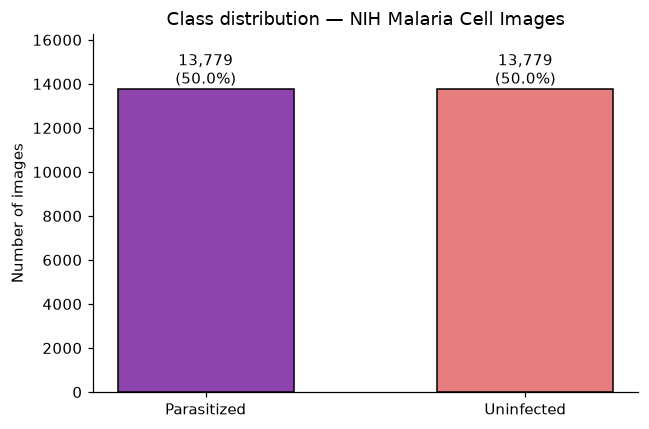

label
Parasitized    13779
Uninfected     13779
Total: 27,558 | imbalance ratio (majority/minority): 1.000
Verdict: BALANCED — no resampling or class weights needed


In [4]:
counts = df["label"].value_counts().reindex(CLASSES)
ratio = counts.max() / counts.min()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[COLORS[c] for c in counts.index], edgecolor="black", width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set_title("Class distribution — NIH Malaria Cell Images")
ax.set_ylabel("Number of images"); ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.savefig(FIG_DIR / "class_distribution.png"); plt.show()

print(counts.to_string())
print(f"Total: {counts.sum():,} | imbalance ratio (majority/minority): {ratio:.3f}")
print("Verdict:", "BALANCED — no resampling or class weights needed" if ratio < 1.1 else "IMBALANCED — consider class weights / resampling")

### B.2 Image properties (size, channels, format, integrity, duplicates)

Every image is opened once. For each one we record its size, colour mode and format, an MD5 hash (to find exact duplicates), the fraction of black background padding around the cell, the mean colour of the cell itself, and per-channel sums used later to compute normalisation statistics from the training split only.

In [5]:
NORM_RES = 128   # resolution used for the custom CNN in Submissions 3-4
MEAN_RES = 64    # resolution for the per-class "average cell" image
BLACK_T  = 30    # pixel is background if R+G+B <= BLACK_T

def inspect(path):
    raw = path.read_bytes()
    with Image.open(path) as im:
        fmt, mode, (w, h) = im.format, im.mode, im.size
        rgb = im.convert("RGB")
    arr = np.asarray(rgb, dtype=np.float32)
    fg = arr.sum(axis=2) > BLACK_T
    small = np.asarray(rgb.resize((NORM_RES, NORM_RES), Image.BILINEAR), dtype=np.float64) / 255.0
    tiny  = np.asarray(rgb.resize((MEAN_RES, MEAN_RES), Image.BILINEAR), dtype=np.float64) / 255.0
    cell_rgb = arr[fg].mean(axis=0) if fg.any() else np.full(3, np.nan)
    return dict(md5=hashlib.md5(raw).hexdigest(), file_kb=len(raw) / 1024, format=fmt, mode=mode,
                width=w, height=h, bg_frac=1 - fg.mean(),
                cell_r=cell_rgb[0], cell_g=cell_rgb[1], cell_b=cell_rgb[2],
                s_r=small[..., 0].sum(), s_g=small[..., 1].sum(), s_b=small[..., 2].sum(),
                q_r=(small[..., 0] ** 2).sum(), q_g=(small[..., 1] ** 2).sum(), q_b=(small[..., 2] ** 2).sum()), tiny

t0 = time.time()
rows, bad = [], []
mean_img = {c: np.zeros((MEAN_RES, MEAN_RES, 3)) for c in CLASSES}
for p, label in tqdm(zip(df["path"], df["label"]), total=len(df), desc="Scanning"):
    try:
        info, tiny = inspect(p)
        mean_img[label] += tiny
        rows.append(info)
    except Exception as e:
        bad.append((p, repr(e))); rows.append({})
props = pd.DataFrame(rows, index=df.index)
df = pd.concat([df, props], axis=1)
df["aspect"] = df["width"] / df["height"]
for c in CLASSES:
    mean_img[c] /= (df["label"] == c).sum()
print(f"Scan finished in {time.time() - t0:.1f} s | unreadable/corrupt files: {len(bad)}")
for p, e in bad[:10]: print("  ", p, e)

Scanning: 100%|████████████████████████████████| 27558/27558 [00:29<00:00, 935.52it/s]

Scan finished in 29.5 s | unreadable/corrupt files: 0


In [6]:
summary = df.groupby("label")[["width", "height", "aspect", "file_kb", "bg_frac"]].describe(percentiles=[.5]).T
summary = summary.loc[(slice(None), ["mean", "std", "min", "50%", "max"]), :].round(2)
display(summary)

print("Formats:", df["format"].value_counts().to_dict())
print("Colour modes:", df["mode"].value_counts().to_dict(), "-> channels after RGB conversion: 3")
print(f"Width  range: {df.width.min()}–{df.width.max()} px (median {df.width.median():.0f})")
print(f"Height range: {df.height.min()}–{df.height.max()} px (median {df.height.median():.0f})")
print(f"Images smaller than {NORM_RES}px on the longer side: {(df[['width','height']].max(axis=1) < NORM_RES).mean():.1%}")

dup_groups = df[df.duplicated("md5", keep=False)].groupby("md5")
n_dup_imgs = int(df.duplicated("md5").sum())
cross = sum(g["label"].nunique() > 1 for _, g in dup_groups)
print(f"Exact duplicate images (beyond the first copy): {n_dup_imgs} | duplicate groups with CONFLICTING labels: {cross}")

label         Parasitized  Uninfected
width   mean       133.63      131.34
        std         21.19       18.70
        min         46.00       49.00
        50%        133.00      130.00
        max        394.00      247.00
height  mean       134.39      131.58
        std         21.99       19.05
        min         40.00       49.00
        50%        133.00      130.00
        max        385.00      235.00
aspect  mean         1.01        1.01
        std          0.15        0.14
        min          0.46        0.49
        50%          1.00        1.00
        max          2.59        2.09
file_kb mean        12.66       10.87
        std          3.06        2.56
        min          1.38        1.71
        50%         12.47       10.70
        max         36.00       34.41
bg_frac mean         0.29        0.28
        std          0.06        0.06
        min          0.14        0.14
        50%          0.28        0.26
        max          0.70        0.68

Formats: {'PNG': 27558}
Colour modes: {'RGB': 27558} -> channels after RGB conversion: 3
Width  range: 46–394 px (median 130)
Height range: 40–385 px (median 130)
Images smaller than 128px on the longer side: 28.2%
Exact duplicate images (beyond the first copy): 0 | duplicate groups with CONFLICTING labels: 0


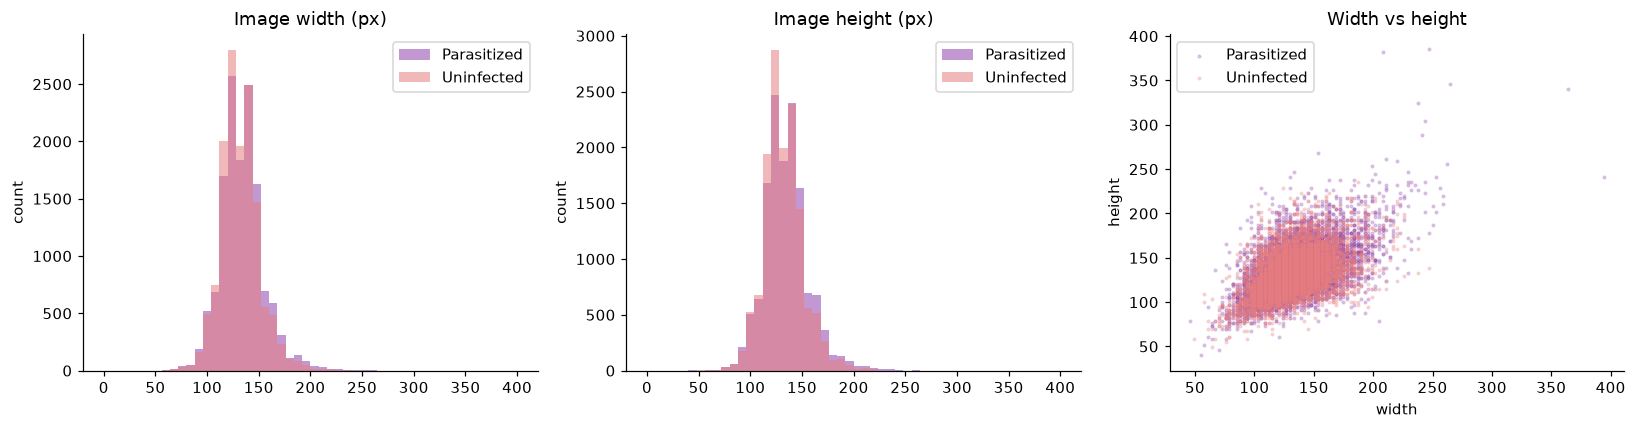

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.arange(0, df[["width", "height"]].max().max() + 10, 8)
for c in CLASSES:
    sub = df[df.label == c]
    axes[0].hist(sub.width,  bins=bins, alpha=.55, label=c, color=COLORS[c])
    axes[1].hist(sub.height, bins=bins, alpha=.55, label=c, color=COLORS[c])
    axes[2].scatter(sub.width, sub.height, s=3, alpha=.25, label=c, color=COLORS[c])
axes[0].set_title("Image width (px)"); axes[1].set_title("Image height (px)")
axes[2].set_title("Width vs height"); axes[2].set_xlabel("width"); axes[2].set_ylabel("height")
for a in axes[:2]: a.set_ylabel("count")
for a in axes: a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "image_sizes.png"); plt.show()

### B.3 Sample image grid (5 random images per class)

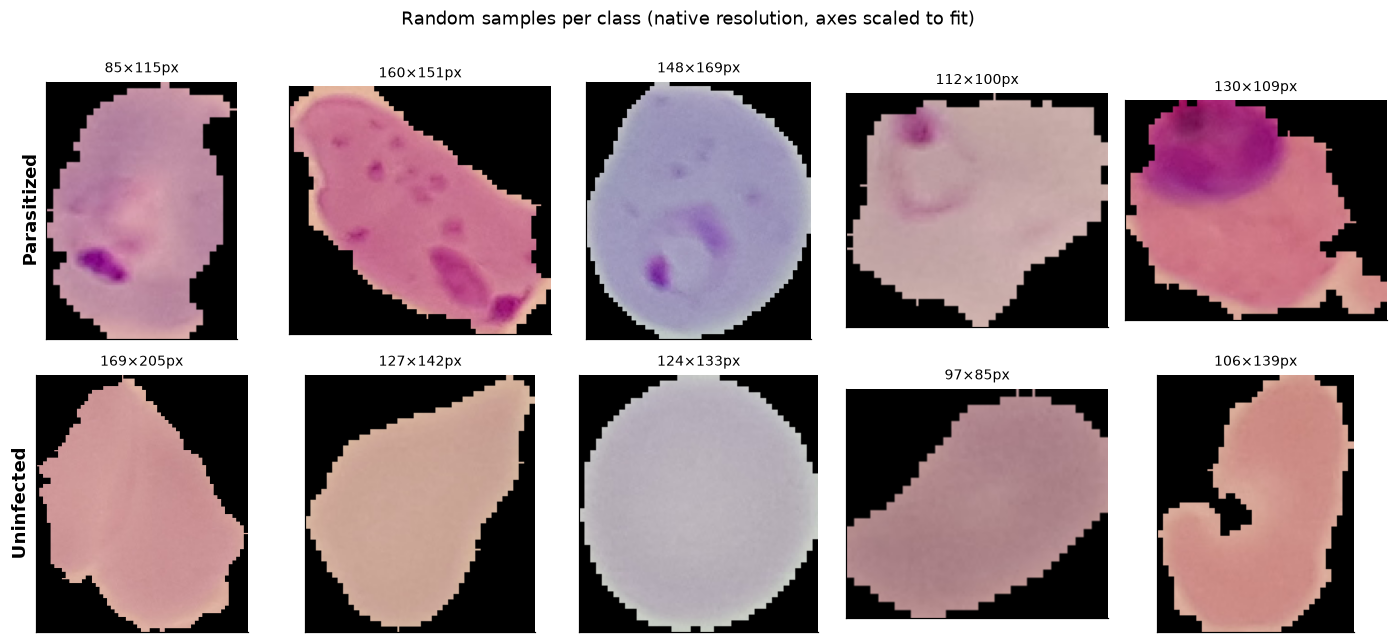

In [8]:
N_PER_CLASS = 5
fig, axes = plt.subplots(len(CLASSES), N_PER_CLASS, figsize=(2.6 * N_PER_CLASS, 2.9 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    sample = df[df.label == c].sample(N_PER_CLASS, random_state=SEED)
    for k, (_, row) in enumerate(sample.iterrows()):
        ax = axes[r, k]
        ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(f"{row.width}×{row.height}px", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        if k == 0: ax.set_ylabel(c, fontsize=12, fontweight="bold")
fig.suptitle("Random samples per class (native resolution, axes scaled to fit)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "sample_grid.png", bbox_inches="tight"); plt.show()

### B.4 Colour, background and the "average cell"

These plots test three things that drive our preprocessing and model choices: how much of each image is useless black padding, whether the two classes differ in overall colour (stain) or only in a small local region (the parasite), and where in the image the evidence is located.

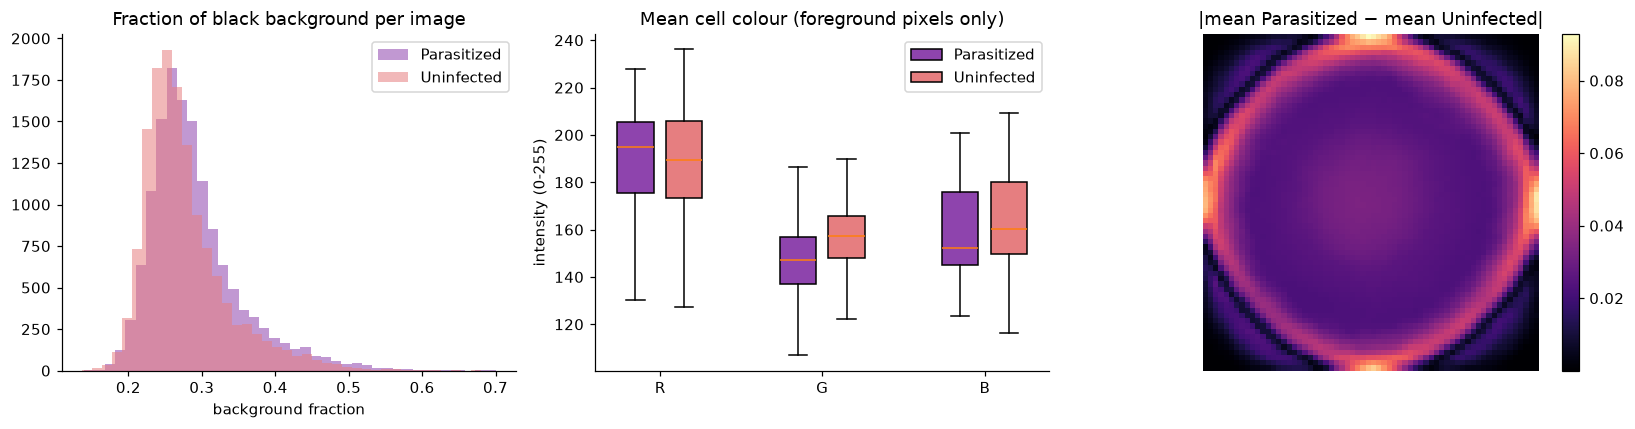

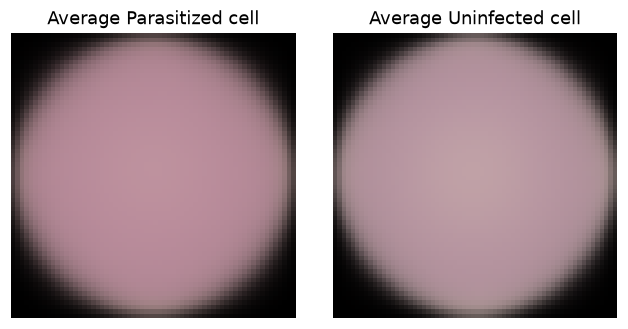

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for c in CLASSES:
    axes[0].hist(df.loc[df.label == c, "bg_frac"], bins=40, alpha=.55, color=COLORS[c], label=c)
axes[0].set_title("Fraction of black background per image"); axes[0].set_xlabel("background fraction"); axes[0].legend()

data = [df.loc[df.label == c, ch].dropna() for ch in ["cell_r", "cell_g", "cell_b"] for c in CLASSES]
pos = [1, 1.6, 3, 3.6, 5, 5.6]
bp = axes[1].boxplot(data, positions=pos, widths=.45, patch_artist=True, showfliers=False)
for patch, c in zip(bp["boxes"], CLASSES * 3): patch.set_facecolor(COLORS[c])
axes[1].set_xticks([1.3, 3.3, 5.3]); axes[1].set_xticklabels(["R", "G", "B"])
axes[1].set_title("Mean cell colour (foreground pixels only)"); axes[1].set_ylabel("intensity (0-255)")
axes[1].legend([bp["boxes"][0], bp["boxes"][1]], CLASSES)

diff = np.abs(mean_img["Parasitized"] - mean_img["Uninfected"]).mean(axis=2)
im = axes[2].imshow(diff, cmap="magma"); plt.colorbar(im, ax=axes[2], fraction=.046)
axes[2].set_title("|mean Parasitized − mean Uninfected|"); axes[2].axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "colour_background.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, c in zip(axes, CLASSES):
    ax.imshow(np.clip(mean_img[c], 0, 1)); ax.set_title(f"Average {c} cell"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "average_cells.png"); plt.show()

### B.5 Leakage-safe train / validation / test split (reused in Submissions 2–4)

Each filename encodes the smear photograph it was cut from (the part before `_cell_`). Cells from the same photograph share lighting, focus and stain, so a purely random split would put near-identical context into both training and test sets and inflate scores. We therefore split **by source photograph** with `StratifiedGroupKFold`, giving about 71 / 14 / 14 % with balanced classes, after removing exact duplicate files. The split and the training-set normalisation statistics are saved so every later submission uses exactly the same data.

In [10]:
clean = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
clean["source_id"] = clean["filename"].str.split("_cell_").str[0]
print(f"Images after removing exact duplicates: {len(clean):,} | distinct source photographs: {clean.source_id.nunique():,}")

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_idx, test_idx = next(sgkf.split(clean, clean.label, groups=clean.source_id))
trval = clean.iloc[trval_idx]
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_i, va_i = next(sgkf2.split(trval, trval.label, groups=trval.source_id))

clean["split"] = "test"
clean.loc[trval.index[tr_i], "split"] = "train"
clean.loc[trval.index[va_i], "split"] = "val"

# sanity checks: no photograph appears in more than one split
assert clean.groupby("source_id")["split"].nunique().max() == 1

tab = pd.crosstab(clean.split, clean.label, margins=True).reindex(["train", "val", "test", "All"])
tab["share_of_total"] = (tab["All"] / len(clean)).map("{:.1%}".format)
display(tab)

tr = clean[clean.split == "train"]
n_px = len(tr) * NORM_RES * NORM_RES
mean = np.array([tr.s_r.sum(), tr.s_g.sum(), tr.s_b.sum()]) / n_px
std = np.sqrt(np.array([tr.q_r.sum(), tr.q_g.sum(), tr.q_b.sum()]) / n_px - mean ** 2)
stats = {"resolution": NORM_RES, "mean": mean.round(4).tolist(), "std": std.round(4).tolist(),
         "note": "computed on TRAIN split only, pixels scaled to [0,1], includes black background"}
json.dump(stats, open(OUT_DIR / "norm_stats.json", "w"), indent=2)
clean[["relpath", "label", "split", "source_id", "width", "height"]].to_csv(OUT_DIR / "splits.csv", index=False)
print("Train-set normalisation stats:", stats)
print("Saved:", OUT_DIR / "splits.csv", "and", OUT_DIR / "norm_stats.json")

Images after removing exact duplicates: 27,558 | distinct source photographs: 1,408


label,Parasitized,Uninfected,All,share_of_total
split,,,,
train,9834,9827,19661,71.3%
val,1973,1976,3949,14.3%
test,1972,1976,3948,14.3%
All,13779,13779,27558,100.0%


Train-set normalisation stats: {'resolution': 128, 'mean': [0.5296, 0.4241, 0.453], 'std': [0.3359, 0.2717, 0.2871], 'note': 'computed on TRAIN split only, pixels scaled to [0,1], includes black background'}
Saved: splits/splits.csv and splits/norm_stats.json


In [11]:
# Key numbers for the written findings below
print(f"Total images: {len(df):,} | per class: {df.label.value_counts().to_dict()}")
print(f"Median size: {df.width.median():.0f}×{df.height.median():.0f}px | range {df.width.min()}–{df.width.max()} × {df.height.min()}–{df.height.max()}")
print(f"Median background fraction: {df.bg_frac.median():.1%}")
print(f"Corrupt files: {len(bad)} | exact duplicates removed: {n_dup_imgs} | conflicting-label duplicates: {cross}")

Total images: 27,558 | per class: {'Parasitized': 13779, 'Uninfected': 13779}
Median size: 130×130px | range 46–394 × 40–385
Median background fraction: 27.0%
Corrupt files: 0 | exact duplicates removed: 0 | conflicting-label duplicates: 0


### B.6 Written findings

**Class balance.** The dataset is perfectly balanced (13,779 images per class, ratio 1.00). Accuracy is therefore a meaningful headline metric, and we need no oversampling, undersampling or class weights. We will still report precision, recall and F1 per class, because in screening a missed parasitized cell (false negative) costs more than a false alarm, so **recall on the Parasitized class** is the metric we watch most closely.

**Image size and format.** All images are 3-channel RGB PNGs, but their sizes vary because each is a cell cropped to its own bounding box (see the size histograms and summary table). A CNN needs a fixed input, so every image will be resized: **128×128** for our custom CNN (Submissions 3–4) and **224×224** for the ImageNet-pretrained models (Submission 2). Most cells are smaller than 224 px, so the pretrained models will see upsampled images; this is standard practice and costs no information.

**Background noise.** A large share of every image is black padding outside the circular cell, and the uninfected class also contains staining artefacts and impurities that look like small dark spots. These are the main sources of "noise": pixels that carry no diagnostic information, and spots that can be confused with a parasite.

**Class similarity.** The average-cell images of both classes look almost identical (a round pink disc), and the mean cell colours overlap heavily. The classes are **not** separable by global colour or shape; the only difference is a small, purple-stained parasite that can appear **anywhere** inside the cell, as the diffuse difference map shows. This is exactly the situation where a spatial/channel **attention module** (Submission 4) should help, since it can learn to suppress the background and focus on the small stained region.

**Stain and lighting variation.** Colour and brightness vary between smear photographs (different slides, stain intensity and smartphone exposure). A model could learn photograph-specific cues instead of parasites, so we split the data **by source photograph** to keep test scores honest.

**Integrity.** The code checks every file for corruption and exact duplicates; duplicates are removed before splitting so the same image cannot appear in both training and test data.

### Preprocessing and augmentation plan (justified by the findings)

| Step | Choice | Reason from EDA |
|---|---|---|
| Resize | 128×128 (custom CNN), 224×224 (pretrained) | Variable native sizes |
| Scaling / normalisation | Pixels to [0,1], then train-set mean/std (custom) or ImageNet mean/std (pretrained) | Stain/brightness differences between photographs |
| Split | 71/14/14 by source photograph, stratified, saved to `splits/splits.csv` | Prevent leakage between near-identical cells |
| Rotation (0–360°) + horizontal/vertical flips | Training only | Cells are round and have no natural orientation; parasite position is random |
| Mild colour jitter (brightness, contrast, saturation ±10–15%) | Training only | Simulates stain and exposure variation |
| Small zoom/shift (≤10%) | Training only | Robustness to segmentation/cropping differences |
| **Avoided:** aggressive random crops | — | The parasite is often near the cell edge and could be cropped out, creating label noise |
| Class weights / resampling | Not used | Classes are balanced |

## C. Related work summary

| # | Paper (author, year) | Dataset used | Model(s) | Approach | Result | Reference link |
|---|---|---|---|---|---|---|
| 1 | Liang et al., 2016 — *CNN-based image analysis for malaria diagnosis* (IEEE BIBM) | NLM thin-smear red-blood-cell images (earlier version of this collection) | Custom 16-layer CNN vs. transfer-learned AlexNet | Trained a CNN from scratch on segmented cells and compared it with transfer learning; cell-level cross-validation | Accuracy **97.37%**; custom CNN beat AlexNet transfer learning | https://doi.org/10.1109/BIBM.2016.7822567 |
| 2 | Rajaraman et al., 2018 — *Pre-trained CNNs as feature extractors toward improved malaria parasite detection in thin blood smear images* (PeerJ) | NIH Malaria Cell Images (27,558 cells) — the dataset's original release | AlexNet, VGG-16, ResNet-50, Xception, DenseNet-121, custom CNN | Transfer learning: pretrained CNNs used as **feature extractors**, choosing the optimal layer for features; evaluated at cell and **patient level**; statistical validation | Best (ResNet-50, patient level): accuracy **95.9%**, F1 **0.959**, AUC **0.991**, MCC 0.917 | https://doi.org/10.7717/peerj.4568 |
| 3 | Rajaraman, Jaeger & Antani, 2019 — *Performance evaluation of deep neural ensembles toward malaria parasite detection in thin-blood smear images* (PeerJ) | NIH Malaria Cell Images (27,558 cells) | Custom CNN (Talos-tuned), VGG-19, SqueezeNet, InceptionResNet-V2; averaging ensembles | Resized to 100×100, mean-normalised; on-the-fly augmentation (rotation, translation, shear, zoom, flip); full **fine-tuning** at LR 1e-4 with Adam; patient-level 5-fold CV; model-averaging ensemble | Ensemble VGG-19 + SqueezeNet: accuracy **99.51%**, F1 **0.995**, AUC **0.999**. Custom CNN alone: 99.09% | https://doi.org/10.7717/peerj.6977 |
| 4 | Fuhad et al., 2020 — *Deep learning based automatic malaria parasite detection from blood smear and its smartphone based application* (Diagnostics) | NIH Malaria Cell Images (27,558 cells; 150 infected and 50 healthy patients) | Several lightweight custom CNNs | Data augmentation; three training schemes — general, **knowledge distillation** and **autoencoder** training — to make tiny models; deployed on phones and a web app | Accuracy **99.23%** with only ~4,600 FLOPs; inference under 1 s per sample on phones | https://doi.org/10.3390/diagnostics10050329 |
| 5 | Ghosh et al., 2025 — *A convolutional neural network with attention mechanism-based malaria detection from blood smear images* (Int. J. Advances in Applied Sciences) | Three public NIH/Kaggle malaria datasets combined | Custom CNN **with attention**; ResNet-50 and DenseNet baselines | Attention module integrated into a custom CNN; transfer-learning comparison; Grad-CAM and saliency maps for interpretability | Accuracy **98.20%**, precision 97.85%, recall 98.55%, F1 **98.20%** (ResNet-50 F1 95.05%) | https://doi.org/10.11591/ijaas.v14.i4.pp1010-1017 |

**What the literature tells us for our project**
* Scores on this dataset are already very high (97–99.5%), so differences between models will be small. Careful evaluation (leakage-safe split, per-class recall, confusion matrices) matters more than chasing the last decimal.
* Papers 1, 3 and 4 show that a well-designed **custom CNN can match or beat transfer learning** here (Rajaraman 2019's custom CNN reached 99.09%), which sets a realistic target for our Submission 3 model.
* Papers 2 and 3 show that **patient-/image-level splitting** gives more honest numbers than random cell-level splits, which supports our grouped split.
* Paper 5 shows an **attention-based custom CNN** outperforming pretrained ResNet-50 and DenseNet, which motivates our Submission 4 experiment of adding CBAM/SE to the Submission 3 network.

---
*All cells were run top to bottom before pushing, so every plot and table above is saved in this notebook. Figures are also saved in `figures/`, and the data split used by Submissions 2–4 is saved in `splits/`.*